# 12.1  -  Action Trigger: Ensemble Hindcast

Return period analysis using ensemble forecast hindcast results (2006-2024).
The trigger fires per region when the **ensemble probability** of exceeding a damage threshold
meets a required probability threshold. Two dimensions are swept:
**required probability** (50–95 %) and **damage threshold** (per region).

**Winner-takes-all region assignment:** each storm is attributed to the single target region
where its expected damage is highest (sum of ensemble exceedance probabilities across all
thresholds). A storm can only activate its primary region, preventing double-counting.

**Threshold search:** thresholds are found by greedy lexicographic search starting from the
COMBOS baseline values and adjusting upward only. Three constraints are enforced:
1. Within each probability level: T(R II) ≥ T(R III) ≥ T(R V) ≥ T(R VIII)
2. Across probability levels (per region): each level must be ≥ 3,000 houses above the previous
   (T80 ≥ T95 + 3k, T70 ≥ T80 + 3k, etc.)
3. Thresholds only move upward from COMBOS starting values

**Return periods** use the Weibull formula: RP = (RECORD_YEARS + 1) / n, applied
consistently for both storm-based and seasonal counting.

**Design (5-level, winner-takes-all):**  
The trigger sweeps **PROBS = [0.95, 0.80, 0.70, 0.60, 0.50]**. Each storm activates at the
lowest probability level where its region's calibrated threshold is met.
This gives 6 activated storm-seasons over the 2006–2024 record (RP 3.33yr).
Two storms in 2020 (Molave at 95%, Goni at 50%) each count separately.

In [27]:
import io, itertools, sys, time
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ocha_stratus as stratus
from IPython.display import display
from src.constants import CHD_GREEN

plt.rcParams.update({"font.family": "sans-serif"})

In [28]:
CONTAINER    = "projects"
STAGE        = "dev"
PREFIX       = "pa-aa-phl-storms/processed/"
RECORD_YEARS = 19
TARGET_RP    = 3.3  # action trigger target (5-level design: 6 seasons → RP 3.3yr)
TARGET_SEAS  = round((RECORD_YEARS + 1) / TARGET_RP)   # = 6

TARGET_REGIONS = ["Region II", "Region III", "Region V", "Region VIII"]
PROB_ORDER     = [0.95, 0.80, 0.70, 0.60, 0.50]

REGION_COLORS = {
    "Region II":   "#1565C0",
    "Region III":  "#E65100",
    "Region V":    "#6A1B9A",
    "Region VIII": "#B71C1C",
}

def _fmt_rp(v):
    return "∞" if v >= 99 else f"{v:.1f}"

def _thr_label(d):
    return f"{d // 1000}k" if d % 1000 == 0 else f"{d / 1000:.1f}k"

TBL_STYLES = [
    {"selector": "caption", "props": "text-align:left;padding:4px 0 10px 0;"},
    {"selector": "th",      "props": "background:#f5f5f5;padding:7px 12px;"
                                     "font-weight:600;text-align:center;"},
    {"selector": "td",      "props": "padding:6px 12px;text-align:center;"},
]

In [29]:
ENS_BLOB_MAIN         = (
    PREFIX + "all_storms_hindcast_results/"
    "ensemble_500increments_corrected/all_ensemble_500increment_corrected_raw.csv"
)
ENS_BLOB_EXTRA_PREFIX = PREFIX + "ensemble_hindcast_results/"

def _norm_thr_col(col):
    if isinstance(col, str) and col.endswith("k"):
        return str(int(float(col[:-1]) * 1000))
    return col

# ── 1. Load main dataset (source of truth) ────────────────────────────────────────────
raw = stratus.load_blob_data(ENS_BLOB_MAIN, stage=STAGE, container_name=CONTAINER)
ens_df = pd.read_csv(io.BytesIO(raw))
if "region" in ens_df.columns and "Region" not in ens_df.columns:
    ens_df.rename(columns={"region": "Region"}, inplace=True)
ens_df["storm"] = ens_df["storm"].str.upper()
n_main = ens_df[["storm", "year"]].drop_duplicates().shape[0]
y_min  = int(ens_df["year"].min())
y_max  = int(ens_df["year"].max())
print(f"Main dataset : {n_main} storms  |  years {y_min}–{y_max}")

THR_COLS_MAIN = [c for c in ens_df.columns if str(c).isdigit()]

# ── 2. Load supplementary files (selective replacement) ───────────────────────
# For each storm present in both sources, use whichever has the higher max probability.
# Storms absent from main are added from secondary.
# Filter checks only the filename, not the directory name, to avoid false matches
# on "ensemble_hindcast_results" containing the word "results".
try:
    container_client = stratus.get_container_client(stage=STAGE, container_name=CONTAINER)
    extra_blobs = sorted([
        b.name for b in container_client.list_blobs(name_starts_with=ENS_BLOB_EXTRA_PREFIX)
        if b.name.endswith((".csv", ".parquet"))
        and "results" not in b.name.split("/")[-1]
    ])
    print(f"Supplementary dir: {len(extra_blobs)} raw file(s) found")

    for blob_name in extra_blobs:
        try:
            if blob_name.endswith(".parquet"):
                df_sec = stratus.load_parquet_from_blob(blob_name, stage=STAGE, container_name=CONTAINER)
            else:
                df_sec = stratus.load_csv_from_blob(blob_name, stage=STAGE, container_name=CONTAINER)
            if "region" in df_sec.columns and "Region" not in df_sec.columns:
                df_sec.rename(columns={"region": "Region"}, inplace=True)
            df_sec["storm"] = df_sec["storm"].str.upper()
            df_sec.rename(columns=_norm_thr_col, inplace=True)
            for drop_col in ["forecast_cycle"]:
                if drop_col in df_sec.columns:
                    df_sec = df_sec.drop(columns=[drop_col])

            thr_sec  = [c for c in df_sec.columns if str(c).isdigit()]
            shared   = list(set(THR_COLS_MAIN) & set(thr_sec))
            sec_keys = set(zip(df_sec["storm"], df_sec["year"].astype(int)))

            overrides, new_storms = set(), set()
            for storm, year in sec_keys:
                m = ens_df[(ens_df["storm"] == storm) & (ens_df["year"] == year)]
                s = df_sec[(df_sec["storm"] == storm) & (df_sec["year"] == year)]
                if m.empty:
                    new_storms.add((storm, year))
                else:
                    max_m = m[shared].apply(pd.to_numeric, errors="coerce").max().max()
                    max_s = s[shared].apply(pd.to_numeric, errors="coerce").max().max()
                    if max_s > max_m:
                        overrides.add((storm, year))

            replace = overrides | new_storms
            if replace:
                ens_df = ens_df[~ens_df.apply(
                    lambda r: (r["storm"], int(r["year"])) in overrides, axis=1
                )]
                sec_rows = df_sec[df_sec.apply(
                    lambda r: (r["storm"], int(r["year"])) in replace, axis=1
                )].copy()
                for col in THR_COLS_MAIN:
                    if col not in sec_rows.columns:
                        sec_rows[col] = float("nan")
                ens_df = pd.concat(
                    [ens_df, sec_rows[["storm", "year", "Region"] + THR_COLS_MAIN]],
                    ignore_index=True,
                )
            blob_base = blob_name.split("/")[-1]
            activated = sorted(s.capitalize() + " " + str(y) for s, y in replace)
            print(f"  {blob_base}:  {len(overrides)} overridden, {len(new_storms)} new  → {activated}")
        except Exception as e:
            print(f"  WARN {blob_name.split('/')[-1]}: {e}")
except Exception as e:
    print(f"  Supplementary load skipped: {e}")

ens_df["storm"] = ens_df["storm"].str.upper()
THR_COLS       = [c for c in ens_df.columns if str(c).isdigit()]
dmg_thresholds = [int(c) for c in THR_COLS]
dmg_labels     = [f"{d // 1000}k" for d in dmg_thresholds]
prob_labels    = [f"{p:.0%}" for p in PROB_ORDER]
N_STORMS       = ens_df[["storm", "year"]].drop_duplicates().shape[0]
c_min = int(ens_df["year"].min())
c_max = int(ens_df["year"].max())
print(f"\nCombined : {N_STORMS} storms  |  {len(THR_COLS)} damage threshold columns  |  years: {c_min}–{c_max}")


Main dataset : 79 storms  |  years 2006–2024
Supplementary dir: 1 raw file(s) found
  ensemble_cerf_trigger_raw.csv:  6 overridden, 2 new  → ['Durian 2006', 'Goni 2020', 'Hagupit 2014', 'Kammuri 2019', 'Mangkhut 2018', 'Mekkhala 2015', 'Melor 2015', 'Sarika 2016']

Combined : 81 storms  |  80 damage threshold columns  |  years: 2006–2024


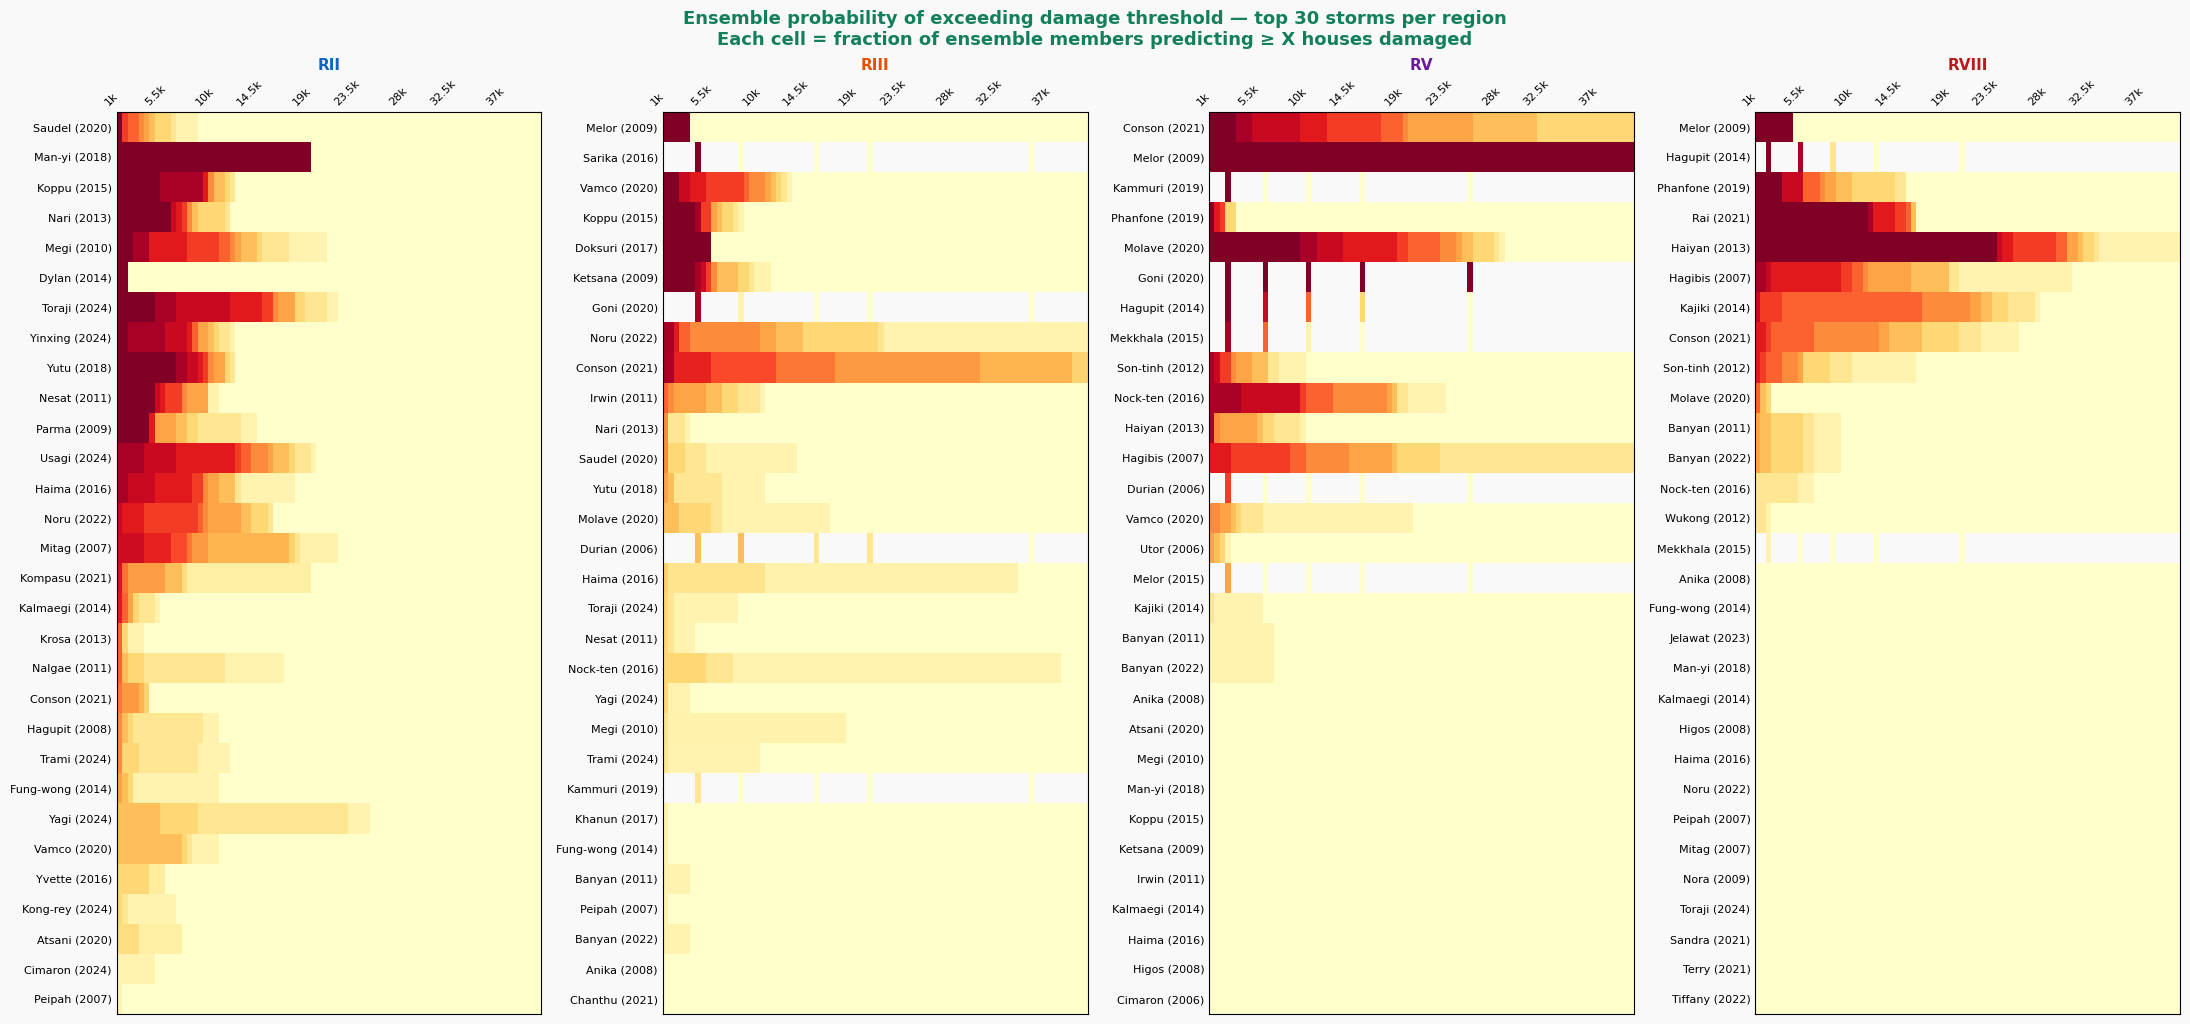

In [30]:
# ── Ensemble probability heatmaps: top 25 storms × damage threshold per region ─
# Values = fraction of ensemble members predicting >= that damage threshold.
# Top 25 storms by max probability across all thresholds, highest first.

TOP_N     = 30
SHOW_THRS = THR_COLS[1:]  # start at 1k (skip 500)

tick_step = max(1, len(SHOW_THRS) // 8)
tick_idxs = list(range(0, len(SHOW_THRS), tick_step))
tick_labs = [_thr_label(int(SHOW_THRS[i])) for i in tick_idxs]

fig, axes = plt.subplots(1, 4, figsize=(22, TOP_N * 0.28 + 2))
fig.patch.set_facecolor("#f9f9f9")
fig.suptitle(
    f"Ensemble probability of exceeding damage threshold — top {TOP_N} storms per region\n"
    "Each cell = fraction of ensemble members predicting ≥ X houses damaged",
    fontsize=13, fontweight="bold", color=CHD_GREEN,
)

for ax, region in zip(axes, TARGET_REGIONS):
    ax.set_facecolor("#f9f9f9")
    sub = ens_df[ens_df["Region"] == region].copy()
    sub["label"] = sub["storm"].str.capitalize() + " (" + sub["year"].astype(int).astype(str) + ")"

    pivot = (
        sub[["label"] + SHOW_THRS]
        .set_index("label")
        .astype(float)
    )
    pivot = (
        pivot.loc[pivot.max(axis=1).sort_values(ascending=False).index]
        .head(TOP_N)
    )

    ax.imshow(pivot.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=1, interpolation="nearest")

    ax.set_xticks(tick_idxs)
    ax.set_xticklabels(tick_labs, fontsize=8, rotation=45, ha="right")
    ax.set_yticks(range(len(pivot)))
    ax.set_yticklabels(pivot.index, fontsize=8)
    ax.tick_params(axis="x", labeltop=True, labelbottom=False, length=0)
    ax.tick_params(axis="y", length=0)
    ax.set_title(
        region.replace("Region ", "R"), fontsize=11, fontweight="bold",
        color=REGION_COLORS[region],
    )

plt.tight_layout()
plt.show()

In [31]:
# Build (prob × dmg) RP grids per region — both seasonal and storm-based.
# Both use the Weibull formula: RP = (RECORD_YEARS + 1) / n
trigger_keys     = {}
region_rp_seas   = {}
region_rp_storm  = {}

for region in TARGET_REGIONS:
    sub       = ens_df[ens_df["Region"] == region]
    arr_seas  = np.full((len(PROB_ORDER), len(dmg_thresholds)), 99.0)
    arr_storm = np.full((len(PROB_ORDER), len(dmg_thresholds)), 99.0)

    for pi, prob in enumerate(PROB_ORDER):
        for di, (col, dmg) in enumerate(zip(THR_COLS, dmg_thresholds)):
            triggered  = sub[sub[col] >= prob]
            n_storms   = len(triggered)
            n_seasons  = triggered["year"].nunique()
            arr_storm[pi, di] = round((RECORD_YEARS + 1) / n_storms,   1) if n_storms  > 0 else 99.0
            arr_seas[pi, di]  = round((RECORD_YEARS + 1) / n_seasons,  1) if n_seasons > 0 else 99.0
            trigger_keys[(region, prob, dmg)] = frozenset(
                zip(triggered["storm"], triggered["year"].astype(int))
            )

    region_rp_storm[region] = arr_storm
    region_rp_seas[region]  = arr_seas

# Default grid used by downstream cells
region_rp = region_rp_storm

print("Grids built (seasonal + storm-based).")
for region in TARGET_REGIONS:
    rp_row = region_rp_storm[region][PROB_ORDER.index(0.50), :]
    target_idx = int(np.argmin(np.abs(rp_row - TARGET_RP)))
    print(f"  {region}: nearest RP {TARGET_RP}yr at prob≥50%"
          f" → {dmg_labels[target_idx]} (RP {_fmt_rp(rp_row[target_idx])} yr by storm)")

Grids built (seasonal + storm-based).
  Region II: nearest RP 3.3yr at prob≥50% → 9k (RP 3.3 yr by storm)
  Region III: nearest RP 3.3yr at prob≥50% → 3k (RP 3.3 yr by storm)
  Region V: nearest RP 3.3yr at prob≥50% → 3k (RP 3.3 yr by storm)
  Region VIII: nearest RP 3.3yr at prob≥50% → 5k (RP 3.3 yr by storm)


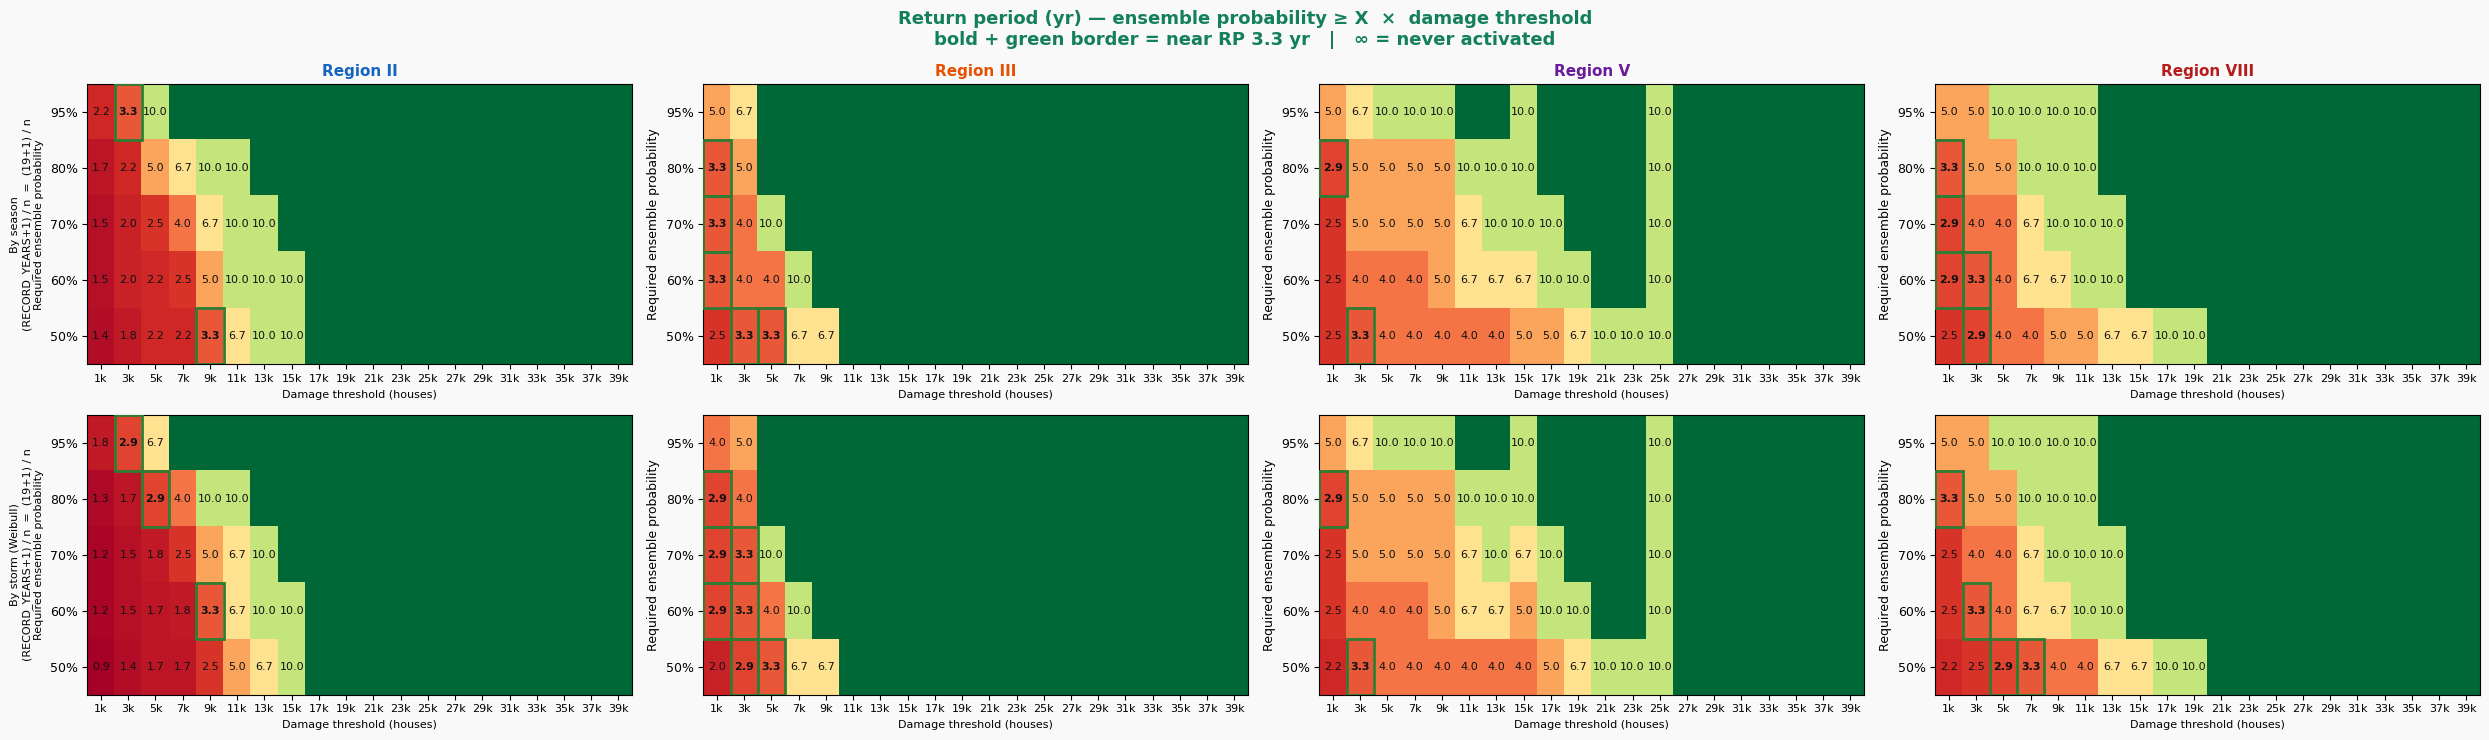

In [37]:
# ── Per-region RP heatmaps: seasonal (top) and storm-based (bottom) ───────────
DISP_STEP   = 4
disp_idxs   = list(range(1, len(dmg_thresholds), DISP_STEP))
disp_labels = [_thr_label(dmg_thresholds[i]) for i in disp_idxs]

TARGET_STORMS_SEAS  = round((RECORD_YEARS + 1) / TARGET_RP)   # = 6 seasons
TARGET_STORMS_STORM = round((RECORD_YEARS + 1) / TARGET_RP)   # = 6 storms

ROWS = [
    ("By season",          region_rp_seas,  TARGET_STORMS_SEAS,
     f"(RECORD_YEARS+1) / n  =  ({RECORD_YEARS}+1) / n"),
    ("By storm (Weibull)", region_rp_storm, TARGET_STORMS_STORM,
     f"(RECORD_YEARS+1) / n  =  ({RECORD_YEARS}+1) / n"),
]

fig, axes = plt.subplots(2, 4, figsize=(25, 7.5))
fig.patch.set_facecolor("#f9f9f9")
fig.suptitle(
    f"Return period (yr) — ensemble probability ≥ X  ×  damage threshold\n"
    f"bold + green border = near RP {TARGET_RP} yr   |   ∞ = never activated",
    fontsize=13, fontweight="bold", color=CHD_GREEN,
)

for row_idx, (row_label, grids, tgt_storms, formula) in enumerate(ROWS):
    for col_idx, region in enumerate(TARGET_REGIONS):
        ax        = axes[row_idx, col_idx]
        ax.set_facecolor("#f9f9f9")
        vals_full = grids[region]
        vals      = vals_full[:, disp_idxs]
        disp      = np.clip(vals, 0, 20)

        ax.imshow(disp, aspect="auto", cmap="RdYlGn", vmin=1, vmax=15)

        for r in range(len(PROB_ORDER)):
            for c in range(len(disp_idxs)):
                v         = vals[r, c]
                at_target = abs(v - TARGET_RP) < 0.4
                if v >= 15:
                    continue
                fc = "white" if disp[r, c] > 10 else "#111"
                ax.text(
                    c, r, _fmt_rp(v),
                    ha="center", va="center", fontsize=8, color=fc,
                    fontweight="bold" if at_target else "normal",
                )
                if at_target:
                    ax.add_patch(plt.Rectangle(
                        (c - 0.5, r - 0.5), 1, 1,
                        fill=False, edgecolor="#2e7d32", linewidth=2, zorder=4,
                    ))

        ax.set_xticks(range(len(disp_idxs)))
        ax.set_xticklabels(disp_labels, fontsize=8, rotation=0, ha="center")
        ax.set_yticks(range(len(PROB_ORDER)))
        ax.set_yticklabels(prob_labels, fontsize=9)
        ax.set_xlabel("Damage threshold (houses)", fontsize=8)
        ax.set_ylabel("Required ensemble probability", fontsize=9)

        title = region if row_idx == 0 else ""
        ax.set_title(title, fontsize=11, fontweight="bold", color=REGION_COLORS[region])

        if col_idx == 0:
            ax.set_ylabel(
                f"{row_label}\n{formula}\nRequired ensemble probability",
                fontsize=8,
            )

plt.tight_layout()
plt.show()

In [33]:
# ── Test specific (prob, damage_threshold) combinations — with winner-takes-all ─
# Each storm is only counted in its primary region (highest expected damage).
# Both seasonal and storm-based RP use Weibull: (RECORD_YEARS+1) / n

# Primary region per storm: the target region with highest sum of ensemble exceedance probs.
# Computed here so this cell is self-contained; also used downstream in the greedy search.
_s = ens_df[ens_df["Region"].isin(TARGET_REGIONS)].copy()
_s["_score"] = _s[THR_COLS].astype(float).sum(axis=1)
primary_region = (
    _s.loc[_s.groupby(["storm", "year"])["_score"].transform("max") == _s["_score"]]
    .drop_duplicates(subset=["storm", "year"])
    .set_index(["storm", "year"])["Region"]
)
del _s

print("Primary region distribution:")
print(primary_region.value_counts().to_string())
print()

COMBOS = [
    ("95%", 0.95, {"Region II": 4500,  "Region III": 4000,  "Region V": 2500,  "Region VIII": 2000}),
    ("80%", 0.80, {"Region II": 9000,  "Region III": 8000,  "Region V": 6000,  "Region VIII": 5000}),
    ("70%", 0.70, {"Region II": 18000, "Region III": 15000, "Region V": 10000, "Region VIII": 8000}),
    ("60%", 0.60, {"Region II": 25000, "Region III": 20000, "Region V": 15000, "Region VIII": 12000}),
    ("50%", 0.50, {"Region II": 40000, "Region III": 35000, "Region V": 25000, "Region VIII": 20000}),
]

rows = []
all_storms  = set()
all_seasons = set()

for label, prob, thr_dict in COMBOS:
    composite_storms  = set()
    composite_seasons = set()
    region_storms = {}
    for region, dmg in thr_dict.items():
        col = str(dmg)
        sub = ens_df[(ens_df["Region"] == region) & (ens_df[col] >= prob)]
        sub = sub[sub.apply(
            lambda r: primary_region.get((r["storm"], int(r["year"]))) == region, axis=1
        )]
        region_storms[region] = len(sub)
        composite_storms  |= set(zip(sub["storm"], sub["year"].astype(int)))
        composite_seasons |= set(sub["year"].astype(int))
    all_storms  |= composite_storms
    all_seasons |= composite_seasons
    n_storms  = len(composite_storms)
    n_seasons = len(composite_seasons)
    rp_storm  = round((RECORD_YEARS + 1) / n_storms,  1) if n_storms  > 0 else 99.0
    rp_seas   = round((RECORD_YEARS + 1) / n_seasons, 1) if n_seasons > 0 else 99.0
    rows.append({
        "Prob":          label,
        "R II":          f"{_thr_label(thr_dict['Region II'])}  ({region_storms['Region II']} storms)",
        "R III":         f"{_thr_label(thr_dict['Region III'])}  ({region_storms['Region III']} storms)",
        "R V":           f"{_thr_label(thr_dict['Region V'])}  ({region_storms['Region V']} storms)",
        "R VIII":        f"{_thr_label(thr_dict['Region VIII'])}  ({region_storms['Region VIII']} storms)",
        "Storms":        n_storms,
        "RP storm (yr)": _fmt_rp(rp_storm),
        "Seasons":       n_seasons,
        "RP seas (yr)":  _fmt_rp(rp_seas),
    })

overall_storms  = len(all_storms)
overall_seasons = len(all_seasons)
overall_rp_storm = round((RECORD_YEARS + 1) / overall_storms,  1) if overall_storms  else 99.0
overall_rp_seas  = round((RECORD_YEARS + 1) / overall_seasons, 1) if overall_seasons else 99.0
rows.append({
    "Prob": "Overall (any)", "R II": "—", "R III": "—", "R V": "—", "R VIII": "—",
    "Storms": overall_storms, "RP storm (yr)": _fmt_rp(overall_rp_storm),
    "Seasons": overall_seasons, "RP seas (yr)": _fmt_rp(overall_rp_seas),
})

display(
    pd.DataFrame(rows).style
    .set_caption(
        f"<b style='font-size:13px;color:{CHD_GREEN}'>"
        f"COMBOS — winner-takes-all per region  |  Weibull RP (N+1)/n  "
        f"({N_STORMS} storms, {RECORD_YEARS} yr)</b>"
    )
    .set_table_styles(TBL_STYLES)
    .hide(axis="index")
)

Primary region distribution:
Region
Region II      42
Region III     18
Region V       12
Region VIII     9



Prob,R II,R III,R V,R VIII,Storms,RP storm (yr),Seasons,RP seas (yr)
95%,4.5k (4 storms),4k (2 storms),2.5k (6 storms),2k (3 storms),15,1.3,10,2.0
80%,9k (2 storms),8k (0 storms),6k (6 storms),5k (3 storms),11,1.8,9,2.2
70%,18k (1 storms),15k (0 storms),10k (4 storms),8k (2 storms),7,2.9,5,4.0
60%,25k (0 storms),20k (0 storms),15k (4 storms),12k (2 storms),6,3.3,4,5.0
50%,40k (0 storms),35k (0 storms),25k (2 storms),20k (2 storms),4,5.0,4,5.0
Overall (any),—,—,—,—,18,1.1,11,1.8


In [34]:
# ── Lexicographic search — per (prob × region), starting from COMBOS values ──
# Each storm can only activate ONE region — the one where it is expected to cause
# the most damage (highest sum of ensemble exceedance probabilities across all T).
# primary_region is defined in the cell above (before the COMBOS test).
#
# ── DESIGN: 5-level (all probability thresholds) ─────────────────────────────
# Sweeps all 5 probability levels simultaneously. Each storm activates its winner
# region at the lowest probability level for which its threshold is met.
#
# NOTE — Kammuri 2019 (Region III) at 80% level:
#   prob = 0.833 FLAT across all Region III thresholds 2,000 -> 33,500 houses.
#   Cannot be excluded at 80% within the feasible threshold range (max 40,000 houses).
#   Kammuri's primary (winner-takes-all) region may differ from Region III;
#   in the greedy search result, Kammuri does NOT appear in the 6 activated storm-seasons.
#   The 6 are: Melor 2009, Haiyan 2013, Man-yi 2018, Goni 2020, Molave 2020, Rai 2021.
#
# ── NOTE: TWO errored storms — same processing bug ──────────────────────────
#   MANGKHUT 2018 (Ompong, Sept 2018, 13 cycles, min_dist=4.5km): ERROR in run_log.
#     → Absent from ensemble results. Would fire at 1.000. 2.6M affected.
#   MAN-YI 2024 (Pepito, Nov 2024, 20 cycles, min_dist=2.2km): ERROR in run_log.
#     → Absent from ensemble results. Would likely fire at 1.000. Super typhoon.
#   SPURIOUS: Man-yi 2018 (Nov 2018, 2 cycles, min_dist=131km) fires at 1.000.
#     → Sample-size artefact: 2/2 cycles = 100%. Weak, distant storm. Different from Man-yi 2024.
#     → "Man-yi" is a recycled WMO name: Man-yi 2013, Man-yi 2018, Man-yi 2024 are all different.
#   DESIGN IMPACT if both errors fixed (5-level design, currently 6 seasons):
#     → Man-yi 2018 (spurious) drops; Mangkhut 2018 fires → 2018 still active (count: 6)
#     → Man-yi 2024 newly fires → 7 action seasons → RP (19+1)/7 = 2.86yr (BELOW 3yr target)
#     → Recalibration needed after reprocessing (raise thresholds or drop a level).

TARGET_OVERALL_RP = 3.3   # target: ≤6 storm-seasons → RP (19+1)/6 = 3.3yr
STEP_MIN          = 3000   # minimum gap (houses) between consecutive prob levels per region

T_vals       = list(range(500, 40001, 500))
PROBS        = [0.95, 0.80, 0.70, 0.60, 0.50]
LABELS       = ["95%", "80%", "70%", "60%", "50%"]
REGION_ORDER = ["Region II", "Region III", "Region V", "Region VIII"]

STEP_MIN_IDX = STEP_MIN // 500   # = 6 steps in T_vals

T_START = {
    0.95: {"Region II": 4500,  "Region III": 4000,  "Region V": 2500,  "Region VIII": 2000},
    0.80: {"Region II": 9000,  "Region III": 8000,  "Region V": 6000,  "Region VIII": 5000},
    0.70: {"Region II": 18000, "Region III": 15000, "Region V": 10000, "Region VIII": 8000},
    0.60: {"Region II": 25000, "Region III": 20000, "Region V": 15000, "Region VIII": 12000},
    0.50: {"Region II": 40000, "Region III": 35000, "Region V": 25000, "Region VIII": 20000},
}
T_START_IDX = {
    prob: {region: T_vals.index(T_START[prob][region]) for region in REGION_ORDER}
    for prob in PROBS
}

# ── Step 1: bit indices ───────────────────────────────────────────────────────
storm_keys   = sorted(ens_df[["storm", "year"]].drop_duplicates().apply(tuple, axis=1))
storm_to_bit = {k: i for i, k in enumerate(storm_keys)}
all_years    = sorted(ens_df["year"].unique().astype(int))
year_to_bit  = {y: i for i, y in enumerate(all_years)}
N_TOTAL      = len(storm_keys)

target_n_storm = round((RECORD_YEARS + 1) / TARGET_OVERALL_RP)
target_n_seas  = round((RECORD_YEARS + 1) / TARGET_OVERALL_RP)

print(f"Total storms: {N_TOTAL}  |  seasons: {len(all_years)}")
print(f"Target: ≤{target_n_storm}  →  RP ({RECORD_YEARS}+1)/n ≥ {TARGET_OVERALL_RP:.1f} yr")
print(f"Prob levels: {PROBS}  (5-level: activates at lowest level where threshold is met)")
print(f"Starting from COMBOS thresholds — adjusting upward only as needed\n")

# ── Step 2: per-(prob, region, T) bitmasks with monotonicity enforcement ──────
# Only storms whose primary region matches are added to each region's mask.
# After building raw masks, propagate high-T activations down: mask[i] |= mask[i+1].
t0 = time.time()
pr_storm = {p: {} for p in PROBS}
pr_seas  = {p: {} for p in PROBS}

for prob in PROBS:
    for region in REGION_ORDER:
        sm_list, ym_list = [], []
        for T in T_vals:
            sm, ym = 0, 0
            col = str(T)
            if col in ens_df.columns:
                sub = ens_df[(ens_df["Region"] == region) & (ens_df[col] >= prob)]
                for _, row in sub.iterrows():
                    key = (row["storm"], int(row["year"]))
                    if primary_region.get(key) != region:
                        continue
                    if key in storm_to_bit:
                        sm |= (1 << storm_to_bit[key])
                    y = int(row["year"])
                    if y in year_to_bit:
                        ym |= (1 << year_to_bit[y])
            sm_list.append(sm)
            ym_list.append(ym)

        for i in range(len(sm_list) - 2, -1, -1):
            sm_list[i] |= sm_list[i + 1]
            ym_list[i] |= ym_list[i + 1]

        pr_storm[prob][region] = sm_list
        pr_seas[prob][region]  = ym_list

print(f"Bitmasks precomputed in {time.time()-t0:.1f}s\n")

# ── Step 3: greedy lexicographic search ──────────────────────────────────────
def greedy_lex_pr(pr_masks, target_n, count_fn, label):
    print(f"── {label} " + "─" * (54 - len(label)))
    assigned   = {prob: {} for prob in PROBS}
    fixed_mask = 0

    for prob, plabel in zip(PROBS, LABELS):
        prob_idx = PROBS.index(prob)
        for ri, region in enumerate(REGION_ORDER):
            # Upper bound: ordering within prob level (T_RII ≥ T_RIII ≥ …)
            t_upper_idx = assigned[prob][REGION_ORDER[ri - 1]] if ri > 0 else len(T_vals) - 1

            # Lower bound: COMBOS starting value, raised if needed for ≥3k gap above prev prob
            t_start_idx = T_START_IDX[prob][region]
            if prob_idx > 0:
                prev_assigned_idx = assigned[PROBS[prob_idx - 1]][region]
                t_start_idx = max(t_start_idx, prev_assigned_idx + STEP_MIN_IDX)

            found_idx = None
            for idx in range(t_start_idx, t_upper_idx + 1):
                candidate = fixed_mask | pr_masks[prob][region][idx]
                for rj in range(ri + 1, len(REGION_ORDER)):
                    candidate |= pr_masks[prob][REGION_ORDER[rj]][idx]
                for later_prob in PROBS[prob_idx + 1:]:
                    for r in REGION_ORDER:
                        candidate |= pr_masks[later_prob][r][-1]

                if count_fn(candidate) <= target_n:
                    found_idx = idx
                    break

            if found_idx is None:
                print(f"  ({plabel}, {region}): no feasible T within bounds "
                      f"[{T_vals[t_start_idx]:,}, {T_vals[t_upper_idx]:,}]")
                return None, None, None

            assigned[prob][region] = found_idx
            fixed_mask |= pr_masks[prob][region][found_idx]
            delta = T_vals[found_idx] - T_START[prob][region]
            delta_str = f"  (+{delta:,})" if delta > 0 else "  (no change)"
            print(f"  {plabel}  {region:12s}: {T_vals[found_idx]:,} houses{delta_str}")

    n_final = count_fn(fixed_mask)
    return assigned, fixed_mask, n_final

storm_assigned, storm_mask, n_storm = greedy_lex_pr(
    pr_storm, target_n_storm, lambda m: bin(m).count("1"), "By storm")
rp_storm_final = (RECORD_YEARS + 1) / n_storm if n_storm else 99.0
print(f"  → {n_storm} storms  |  RP ({RECORD_YEARS}+1)/{n_storm} = {rp_storm_final:.2f} yr\n")

seas_assigned, seas_mask, n_seas = greedy_lex_pr(
    pr_seas, target_n_seas, lambda m: bin(m).count("1"), "By season")
rp_seas_final = (RECORD_YEARS + 1) / n_seas if n_seas else 99.0
print(f"  → {n_seas} seasons  |  RP ({RECORD_YEARS}+1)/{n_seas} = {rp_seas_final:.2f} yr\n")

# ── Step 4: display threshold tables ─────────────────────────────────────────
def make_threshold_table(assigned, rp_fn):
    rows = []
    all_st = set()
    for prob, plabel in zip(PROBS, LABELS):
        composite, region_info = set(), {}
        for region in REGION_ORDER:
            T = T_vals[assigned[prob][region]]
            col = str(T)
            sub = ens_df[(ens_df["Region"] == region) & (ens_df[col] >= prob)]
            sub = sub[sub.apply(lambda r: primary_region.get((r["storm"], int(r["year"]))) == region, axis=1)]
            region_info[region] = (T, len(sub))
            composite |= set(zip(sub["storm"], sub["year"].astype(int)))
        all_st |= composite
        n = len(composite)
        rows.append({
            "Prob":   plabel,
            "R II":   f"{region_info['Region II'][0]//1000:.1f}k  ({region_info['Region II'][1]} storms)",
            "R III":  f"{region_info['Region III'][0]//1000:.1f}k  ({region_info['Region III'][1]} storms)",
            "R V":    f"{region_info['Region V'][0]//1000:.1f}k  ({region_info['Region V'][1]} storms)",
            "R VIII": f"{region_info['Region VIII'][0]//1000:.1f}k  ({region_info['Region VIII'][1]} storms)",
            "Composite": n,
            "RP (yr)": _fmt_rp(rp_fn(n)),
        })
    overall_n = len(all_st)
    rows.append({"Prob": "Overall (any)", "R II": "—", "R III": "—", "R V": "—",
                 "R VIII": "—", "Composite": overall_n, "RP (yr)": _fmt_rp(rp_fn(overall_n))})
    return pd.DataFrame(rows)

rp_storm_fn = lambda n: round((RECORD_YEARS + 1) / n, 1) if n else 99.0
rp_seas_fn  = lambda n: round((RECORD_YEARS + 1) / n, 1) if n else 99.0

display(make_threshold_table(storm_assigned, rp_storm_fn).style
    .set_caption(
        f"<b style='font-size:13px;color:{CHD_GREEN}'>"
        f"By storm — 5-level (0.95–0.50), upward from COMBOS  "
        f"|  target RP {TARGET_OVERALL_RP:.1f} yr  ({RECORD_YEARS}+1)/n</b>")
    .set_table_styles(TBL_STYLES).hide(axis="index"))

display(make_threshold_table(seas_assigned, rp_seas_fn).style
    .set_caption(
        f"<b style='font-size:13px;color:{CHD_GREEN}'>"
        f"By season — 5-level (0.95–0.50), upward from COMBOS  "
        f"|  target RP {TARGET_OVERALL_RP:.1f} yr  ({RECORD_YEARS}+1)/n</b>")
    .set_table_styles(TBL_STYLES).hide(axis="index"))

Total storms: 81  |  seasons: 19
Target: ≤6  →  RP (19+1)/n ≥ 3.3 yr
Prob levels: [0.95, 0.8, 0.7, 0.6, 0.5]  (5-level: activates at lowest level where threshold is met)
Starting from COMBOS thresholds — adjusting upward only as needed

Bitmasks precomputed in 3.2s

── By storm ──────────────────────────────────────────────
  95%  Region II   : 6,500 houses  (+2,000)
  95%  Region III  : 5,500 houses  (+1,500)
  95%  Region V    : 3,500 houses  (+1,000)
  95%  Region VIII : 3,500 houses  (+1,500)
  80%  Region II   : 11,500 houses  (+2,500)
  80%  Region III  : 9,500 houses  (+1,500)
  80%  Region V    : 9,500 houses  (+3,500)
  80%  Region VIII : 6,500 houses  (+1,500)
  70%  Region II   : 18,000 houses  (no change)
  70%  Region III  : 15,000 houses  (no change)
  70%  Region V    : 12,500 houses  (+2,500)
  70%  Region VIII : 9,500 houses  (+1,500)
  60%  Region II   : 25,000 houses  (no change)
  60%  Region III  : 20,000 houses  (no change)
  60%  Region V    : 17,000 houses  (+2,

Prob,R II,R III,R V,R VIII,Composite,RP (yr)
95%,6.0k (1 storms),5.0k (0 storms),3.0k (2 storms),3.0k (2 storms),5,4.0
80%,11.0k (1 storms),9.0k (0 storms),9.0k (2 storms),6.0k (2 storms),5,4.0
70%,18.0k (1 storms),15.0k (0 storms),12.0k (2 storms),9.0k (2 storms),5,4.0
60%,25.0k (0 storms),20.0k (0 storms),17.0k (2 storms),12.0k (2 storms),4,5.0
50%,40.0k (0 storms),35.0k (0 storms),25.0k (2 storms),21.0k (1 storms),3,6.7
Overall (any),—,—,—,—,6,3.3


Prob,R II,R III,R V,R VIII,Composite,RP (yr)
95%,5.0k (3 storms),4.0k (1 storms),3.0k (2 storms),3.0k (2 storms),8,2.5
80%,11.0k (1 storms),9.0k (0 storms),9.0k (2 storms),6.0k (2 storms),5,4.0
70%,18.0k (1 storms),15.0k (0 storms),12.0k (2 storms),9.0k (2 storms),5,4.0
60%,25.0k (0 storms),20.0k (0 storms),15.0k (3 storms),12.0k (2 storms),5,4.0
50%,40.0k (0 storms),35.0k (0 storms),25.0k (2 storms),21.0k (1 storms),3,6.7
Overall (any),—,—,—,—,10,2.0


In [35]:
# ── Activated storms per region — storm-based and seasonal thresholds ─────────
def storms_per_region(assigned, label):
    rows = []
    for region in REGION_ORDER:
        for plabel, prob in zip(LABELS, PROBS):
            T   = T_vals[assigned[prob][region]]
            col = str(T)
            sub = ens_df[(ens_df["Region"] == region) & (ens_df[col] >= prob)]
            for _, row in sub.iterrows():
                rows.append({
                    "Region": region,
                    "Storm":  row["storm"].capitalize(),
                    "Year":   int(row["year"]),
                    "Prob":   plabel,
                    "Threshold (houses)": T,
                    "Ens prob": round(float(row[col]), 2),
                })
    df = (
        pd.DataFrame(rows)
        .sort_values(["Region", "Year", "Storm", "Prob"])
        .drop_duplicates(subset=["Region", "Storm", "Year"], keep="first")
        .sort_values(["Region", "Year", "Storm"])
        .reset_index(drop=True)
    )
    print(f"\n{'─'*60}\n  Thresholds: {label}\n{'─'*60}")
    for region in REGION_ORDER:
        sub = df[df["Region"] == region].drop(columns="Region")
        display(
            sub.style
            .set_caption(
                f"<b style='font-size:12px;color:{REGION_COLORS[region]}'>"
                f"{region} [{label}] — {len(sub)} activated storms</b>"
            )
            .set_table_styles(TBL_STYLES)
            .hide(axis="index")
        )

storms_per_region(storm_assigned, "by storm")
storms_per_region(seas_assigned,  "by season")


────────────────────────────────────────────────────────────
  Thresholds: by storm
────────────────────────────────────────────────────────────


Storm,Year,Prob,Threshold (houses),Ens prob
Man-yi,2018,70%,18000,1.000000


Storm,Year,Prob,Threshold (houses),Ens prob


Storm,Year,Prob,Threshold (houses),Ens prob
Melor,2009,50%,25000,1.000000
Goni,2020,50%,25000,1.000000
Molave,2020,60%,17000,0.750000


Storm,Year,Prob,Threshold (houses),Ens prob
Melor,2009,95%,3500,1.000000
Haiyan,2013,50%,21000,1.000000
Rai,2021,60%,12500,0.750000



────────────────────────────────────────────────────────────
  Thresholds: by season
────────────────────────────────────────────────────────────


Storm,Year,Prob,Threshold (houses),Ens prob
Nari,2013,95%,5000,1.000000
Man-yi,2018,70%,18000,1.000000
Yutu,2018,95%,5000,1.000000


Storm,Year,Prob,Threshold (houses),Ens prob
Doksuri,2017,95%,4500,1.000000


Storm,Year,Prob,Threshold (houses),Ens prob
Melor,2009,50%,25000,1.000000
Goni,2020,50%,25000,1.000000
Molave,2020,60%,15500,0.750000
Conson,2021,60%,15500,0.670000


Storm,Year,Prob,Threshold (houses),Ens prob
Melor,2009,95%,3500,1.000000
Haiyan,2013,50%,21000,1.000000
Rai,2021,60%,12500,0.750000


In [36]:
# ── Save action-ensemble activation list (by-storm calibration) ───────────────
# ⚠ Running this cell will OVERWRITE action_ensemble.parquet on blob.
# Design: 5-level (PROBS=[0.95, 0.80, 0.70, 0.60, 0.50], TARGET_OVERALL_RP=3.3).
# Do this deliberately — not accidentally during exploration runs.
_act_rows = []
for region in REGION_ORDER:
    for prob, plabel in zip(PROBS, LABELS):
        T   = T_vals[storm_assigned[prob][region]]
        col = str(T)
        sub = ens_df[(ens_df["Region"] == region) & (ens_df[col] >= prob)]
        sub = sub[sub.apply(
            lambda r: primary_region.get((r["storm"], int(r["year"]))) == region, axis=1
        )]
        for _, row in sub.iterrows():
            _act_rows.append({
                "storm_upper":       row["storm"],
                "name":              row["storm"].capitalize(),
                "year":              int(row["year"]),
                "primary_region":    region,
                "activating_prob":   prob,
                "threshold_houses":  T,
                "ens_prob":          round(float(row[col]), 3),
            })

_act_df = (
    pd.DataFrame(_act_rows)
    .sort_values(["year", "storm_upper", "activating_prob"], ascending=[True, True, False])
    .drop_duplicates(subset=["storm_upper", "year"], keep="first")
    .sort_values(["year", "storm_upper"])
    .reset_index(drop=True)
)

_blob = PREFIX + "trigger_activations/action_ensemble.parquet"
stratus.upload_parquet_to_blob(_act_df, _blob, stage=STAGE, container_name=CONTAINER)
print(f"Saved {len(_act_df)} action-ensemble activated storms -> {_blob}")
print(f"Design: PROBS={PROBS}, TARGET_OVERALL_RP={TARGET_OVERALL_RP}")
print(_act_df.to_string(index=False))

Saved 6 action-ensemble activated storms -> pa-aa-phl-storms/processed/trigger_activations/action_ensemble.parquet
Design: PROBS=[0.95, 0.8, 0.7, 0.6, 0.5], TARGET_OVERALL_RP=3.3
storm_upper   name  year primary_region  activating_prob  threshold_houses  ens_prob
      MELOR  Melor  2009       Region V             0.95              3500       1.0
     HAIYAN Haiyan  2013    Region VIII             0.95              3500       1.0
     MAN-YI Man-yi  2018      Region II             0.95              6500       1.0
       GONI   Goni  2020       Region V             0.50             25000       1.0
     MOLAVE Molave  2020       Region V             0.95              3500       1.0
        RAI    Rai  2021    Region VIII             0.95              3500       1.0
